<center><h1>Chen_Sian_HW7</h1></center>

Name: Sian Chen
<br>
Github Username: Ryan6546ea
<br>
USC ID: 3132413754

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
data = pd.read_csv("../data/Frogs_MFCCs.csv")
train_data = data.sample(frac=0.7, random_state=42)
test_data = data.drop(train_data.index)

### (b) Train a classifier for each label

#### (i) Research

Exact match is the fraction of samples with all three labels correct.

Hamming loss is the fraction of incorrect predictions across Family, Genus, and Species.

Here, Hamming score is 1 minus Hamming loss. Higher exact match and Hamming score, and lower Hamming loss, indicate better performance.

#### (ii) Train a SVM for each of the labels

In [3]:
labels = ["Family", "Genus", "Species"]
X_train = train_data.drop(columns=labels + ["RecordID"])
X_test = test_data[X_train.columns]
y_test = test_data[labels]

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
C_values = [0.1, 1, 10, 100, 1000]

# Reuse these metrics for later models.
def evaluate(predictions):
    correct = predictions.eq(y_test)
    score = correct.to_numpy().mean()
    return pd.Series({
        "Exact match": correct.all(axis=1).mean(),
        "Hamming score": score,
        "Hamming loss": 1 - score
    })

rbf_pred = pd.DataFrame(index=test_data.index)

for label in labels:
    search = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf")),
        {
            "estimator__C": C_values,
            "estimator__gamma": [0.1, 1, 10, 100]
        },
        scoring="accuracy", cv=cv, n_jobs=4
    ).fit(X_train, train_data[label])

    rbf_pred[label] = search.predict(X_test)
    print(label, search.best_params_,
          f"CV accuracy: {search.best_score_:.4f}")

rbf_result = evaluate(rbf_pred)
rbf_result

Family {'estimator__C': 10, 'estimator__gamma': 1} CV accuracy: 0.9919
Genus {'estimator__C': 10, 'estimator__gamma': 1} CV accuracy: 0.9903
Species {'estimator__C': 10, 'estimator__gamma': 1} CV accuracy: 0.9893


Exact match      0.988421
Hamming score    0.992126
Hamming loss     0.007874
dtype: float64

Cross-validation selected C = 10 and gamma = 1 for all three labels. Test exact match is 98.84%, Hamming score is 99.21%, and Hamming loss is 0.79%. Thus, all three labels are correct for 98.84% of test samples.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
l1_pred = pd.DataFrame(index=test_data.index)

for label in labels:
    # Fit scaling within each training fold.
    model = make_pipeline(
        StandardScaler(),
        LinearSVC(
            penalty="l1", dual=False,
            max_iter=10000, random_state=42
        )
    )
    search = GridSearchCV(
        model, {"linearsvc__C": C_values},
        scoring="accuracy", cv=cv, n_jobs=4
    ).fit(X_train, train_data[label])

    l1_pred[label] = search.predict(X_test)
    print(label, search.best_params_,
          f"CV accuracy: {search.best_score_:.4f}")

l1_result = evaluate(l1_pred)
l1_result

Family {'linearsvc__C': 0.1} CV accuracy: 0.9333
Genus {'linearsvc__C': 1} CV accuracy: 0.9494
Species {'linearsvc__C': 1} CV accuracy: 0.9559


Exact match      0.915702
Hamming score    0.951058
Hamming loss     0.048942
dtype: float64

Cross-validation selected C = 0.1 for Family and C = 1 for Genus and Species. Test exact match is 91.57%, Hamming score is 95.11%, and Hamming loss is 4.89%. The Gaussian SVM performs better on this test split.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
smote_pred = pd.DataFrame(index=test_data.index)

for label in labels:
    # Scale and resample within each training fold.
    model = make_imb_pipeline(
        StandardScaler(),
        SMOTE(random_state=42),
        LinearSVC(
            penalty="l1", dual=False,
            max_iter=50000, random_state=42
        )
    )
    search = GridSearchCV(
        model, {"linearsvc__C": C_values},
        scoring="accuracy", cv=cv, n_jobs=4
    ).fit(X_train, train_data[label])

    smote_pred[label] = search.predict(X_test)
    print(label, search.best_params_,
          f"CV accuracy: {search.best_score_:.4f}")

smote_result = evaluate(smote_pred)
pd.DataFrame(
    [rbf_result, l1_result, smote_result],
    index=["Gaussian SVM", "L1 SVM", "SMOTE + L1 SVM"]
)

Family {'linearsvc__C': 100} CV accuracy: 0.9162
Genus {'linearsvc__C': 10} CV accuracy: 0.9120
Species {'linearsvc__C': 1} CV accuracy: 0.9543


,Exact match,Hamming score,Hamming loss
Gaussian SVM,0.988421,0.992126,0.007874
L1 SVM,0.915702,0.951058,0.048942
SMOTE + L1 SVM,0.871700,0.932530,0.067470


With SMOTE, test exact match falls from 91.57% to 87.17%, and Hamming loss rises from 4.89% to 6.75%. Hamming score is 93.25%. SMOTE does not improve these overall test scores. The Gaussian SVM performs best on this split.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [6]:
X_all = data[X_train.columns].to_numpy()
cluster_runs = []

for seed in range(50):
    best_score = -float("inf")

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k, n_init=1, random_state=seed
        ).fit(X_all)
        score = calinski_harabasz_score(X_all, model.labels_)

        if score > best_score:
            best_score = score
            best_k = k
            best_labels = model.labels_

    cluster_runs.append((best_k, best_labels))

pd.Series(
    [k for k, _ in cluster_runs], name="k"
).value_counts().sort_index().to_frame("Runs")

,Runs
k,
2,50


The CH index is undefined for k = 1, so I compare k = 2–50.

### (b) Determine which family is the majority

In [7]:
cluster_majorities = []

for _, clusters in cluster_runs:
    majority = data[labels].groupby(clusters).agg(
        lambda column: column.mode().iloc[0]
    )
    cluster_majorities.append(majority)

cluster_majorities[0]

,Family,Genus,Species
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [8]:
true_labels = data[labels].to_numpy()
clustering_results = []

for (_, clusters), majority in zip(cluster_runs, cluster_majorities):
    predicted = majority.loc[clusters].to_numpy()
    wrong = predicted != true_labels
    loss = wrong.mean()

    clustering_results.append({
        "Hamming distance": wrong.sum(axis=1).mean(),
        "Hamming score": 1 - loss,
        "Hamming loss": loss
    })

clustering_results = pd.DataFrame(clustering_results)
clustering_results.agg(["mean", "std"])

,Hamming distance,Hamming score,Hamming loss
mean,8.956220e-01,7.014593e-01,2.985407e-01
std,1.121495e-16,1.121495e-16,5.607473e-17


## 3. ISLR 12.6.2

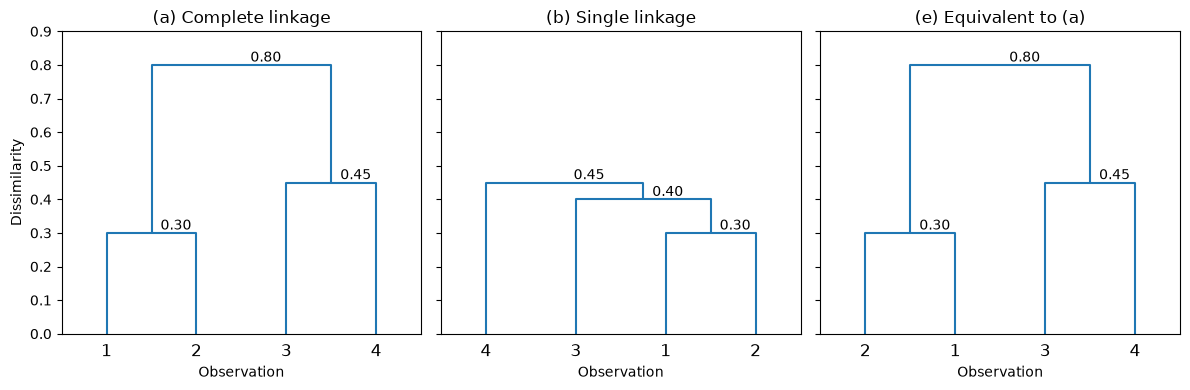

In [9]:
# Distances in the order 12, 13, 14, 23, 24, 34.
distances = [0.3, 0.4, 0.7, 0.5, 0.8, 0.45]
complete = linkage(distances, method="complete")
single = linkage(distances, method="single")

# Swap leaves 1 and 2 without changing the merges.
equivalent = complete.copy()
equivalent[0, :2] = equivalent[0, [1, 0]]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for ax, Z, title in zip(
    axes, [complete, single, equivalent],
    ["(a) Complete linkage", "(b) Single linkage", "(e) Equivalent to (a)"]
):
    tree = dendrogram(
        Z, labels=["1", "2", "3", "4"], color_threshold=0, ax=ax
    )
    for x, y in zip(tree["icoord"], tree["dcoord"]):
        ax.text((x[1] + x[2]) / 2 + 1, y[1] + 0.01, f"{y[1]:.2f}")
    ax.set(title=title, xlabel="Observation", ylim=(0, 0.9))

axes[0].set_ylabel("Dissimilarity")
plt.tight_layout()
plt.show()

(a) Observations 1 and 2 merge at 0.30. Observations 3 and 4 merge at 0.45. The two clusters merge at 0.80.

(b) Observations 1 and 2 merge at 0.30. Observation 3 joins at 0.40. Observation 4 joins at 0.45.

(c) The two clusters are {1, 2} and {3, 4}.

(d) The two clusters are {1, 2, 3} and {4}.

(e) Swap leaves 1 and 2, giving the order 2, 1, 3, 4. The groups and merge heights stay the same, so the dendrogram is equivalent to (a).